In [1]:
import pypsa
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import os
import warnings
warnings.filterwarnings('ignore')

# Prevent Arrow string arrays from breaking PyPSA
try:
    pd.options.future.infer_string = False
except Exception:
    pass

# Font setup (Cambria if available, else default serif)
try:
    font_path = os.path.expanduser('~/Library/Fonts/Cambria.ttc')
    fm.fontManager.addfont(font_path)
    plt.rcParams['font.family'] = 'Cambria'
except Exception:
    plt.rcParams['font.family'] = 'serif'

import platform
if platform.system() == 'Windows':
    base = r"C:\\Users\\sosoq\\Documents\\GitHub\\EdenCampus-PhD\\EdenCampus_PhD"
else:
    base = os.path.expanduser("~/Documents/GitHub/EdenCampus-PhD/EdenCampus_PhD")
for folder in ["01_data/weather", "01_data/demand",
               "04_results/figures", "04_results/tables"]:
    os.makedirs(os.path.join(base, folder), exist_ok=True)

print("Building Eden Campus Digital Twin...")
print("=" * 50)

# ── LOAD INPUTS FROM COMMITTED DATA (single source of truth) ──
# All demand and PV come from committed CSVs via data_prep.py — no live PVGIS,
# no inline synthetic generation. See DATA_RECONCILIATION.md for provenance.
from data_prep import load_inputs

# Representative-week model (4 seasonal weeks x 168 h). For the full 8760 h
# model use Full Year Model.ipynb (representative_weeks=False).
_inputs = load_inputs(base, representative_weeks=True)

time_index     = _inputs["time_index"]
elec_demand    = _inputs["elec_demand"]
thermal_demand = _inputs["thermal_demand"]
pv_profile     = _inputs["pv_profile"]

print(f"Time index: {len(time_index)} hours (4 representative seasonal weeks)")
print(f"PV profile ready. Peak: {pv_profile.max()*100:.1f}% of capacity")
print(f"Electrical demand ready. Peak: {elec_demand.max():.0f} kW")
print(f"Thermal demand ready. Peak: {thermal_demand.max():.0f} kW (MODELLED)")
print("\nAll input data loaded from committed files successfully!")


Building Eden Campus Digital Twin...
Eden Campus inputs loaded from committed data files
  Snapshots:            672 h (representative weeks)
  Elec demand peak:     680.7 kW
  Elec demand annual:   185.2 MWh (subset)
  Thermal demand peak:  754.5 kW (MODELLED)
  PV peak:              80.5 % of 1000 kW
  PV annual (1 MW):     87.4 MWh
Time index: 672 hours (4 representative seasonal weeks)
PV profile ready. Peak: 80.5% of capacity
Electrical demand ready. Peak: 681 kW
Thermal demand ready. Peak: 755 kW (MODELLED)

All input data loaded from committed files successfully!


In [2]:
network = pypsa.Network()
network.set_snapshots(time_index)

print("PyPSA Network created")
print(f"Snapshots: {len(network.snapshots)} hours")
print("=" * 50)

# ── BUSES ──
network.add("Bus", "Electricity Bus", carrier="AC")
network.add("Bus", "Hydrogen Bus",    carrier="hydrogen")
network.add("Bus", "Heat Bus",        carrier="heat")
print("Buses added: Electricity | Hydrogen | Heat")

# ── CARRIERS ──
network.add("Carrier", "AC",       co2_emissions=0.233)
network.add("Carrier", "hydrogen", co2_emissions=0.0)
network.add("Carrier", "heat",     co2_emissions=0.0)

# ── SOLAR PV ──
network.add("Generator", "Solar PV",
            bus="Electricity Bus", carrier="AC",
            p_nom=1000, p_max_pu=pv_profile,
            marginal_cost=0, capital_cost=0)
print("Added: Solar PV (1000 kW)")

# ── GRID IMPORT ──
network.add("Generator", "Grid Import",
            bus="Electricity Bus", carrier="AC",
            p_nom=2000, marginal_cost=0.280, p_min_pu=0)  # £/kWh (280 £/MWh)
print("Added: Grid Import (2000 kW)")

# ── GRID EXPORT ──
network.add("Generator", "Grid Export",
            bus="Electricity Bus", carrier="AC",
            p_nom=500, p_max_pu=0, p_min_pu=-1,
            marginal_cost=-0.050)  # £/kWh (-50 £/MWh SEG)
print("Added: Grid Export (500 kW)")

# ── BESS ──
network.add("StorageUnit", "BESS",
            bus="Electricity Bus", carrier="AC",
            p_nom=500, max_hours=4,
            efficiency_store=0.95, efficiency_dispatch=0.95,
            standing_loss=0.0002, cyclic_state_of_charge=True,
            state_of_charge_initial=0.5)
print("Added: BESS (500 kW / 2000 kWh)")

# ── ELECTROLYSER ──
network.add("Link", "Electrolyser",
            bus0="Electricity Bus", bus1="Hydrogen Bus",
            p_nom=200, efficiency=0.70, marginal_cost=0.001)  # £/kWh
print("Added: Electrolyser (200 kW, 70% efficiency)")

# ── FUEL CELL ──
network.add("Link", "Fuel Cell",
            bus0="Hydrogen Bus", bus1="Electricity Bus",
            p_nom=100, efficiency=0.50, marginal_cost=0.002)  # £/kWh
print("Added: Fuel Cell (100 kW, 50% efficiency)")

# ── HEAT PUMP ──
network.add("Link", "Heat Pump",
            bus0="Electricity Bus", bus1="Heat Bus",
            p_nom=300, efficiency=3.0, marginal_cost=0.0005)  # £/kWh
print("Added: Heat Pump (300 kW, COP=3.0)")

# ── ELECTRICAL DEMAND ──
network.add("Load", "Electrical Demand",
            bus="Electricity Bus", carrier="AC",
            p_set=elec_demand)
print(f"Added: Electrical Demand (peak {elec_demand.max():.0f} kW)")

# ── HYDROGEN TANK (LDES) ──
network.add("Store", "Hydrogen Tank",
            bus="Hydrogen Bus", carrier="hydrogen",
            e_nom=5000, e_cyclic=True,
            e_initial=0.2, standing_loss=0.0001,
            marginal_cost=0)
print("Added: Hydrogen Tank (5000 kWh LDES)")

# ── PCM TES ──
network.add("StorageUnit", "PCM TES",
            bus="Heat Bus", carrier="heat",
            p_nom=200, max_hours=8,
            efficiency_store=0.95, efficiency_dispatch=0.92,
            standing_loss=0.001, cyclic_state_of_charge=True,
            state_of_charge_initial=0.3)
print("Added: PCM TES (200 kW / 1600 kWh thermal)")

# ── BACKUP BOILER ──
network.add("Generator", "Backup Boiler",
            bus="Heat Bus", carrier="heat",
            p_nom=600, marginal_cost=0.110, p_min_pu=0)  # £/kWh (110 £/MWh)
print("Added: Backup Boiler (600 kW)")

# ── THERMAL DEMAND ──
network.add("Load", "Thermal Demand",
            bus="Heat Bus", carrier="heat",
            p_set=thermal_demand)
print(f"Added: Thermal Demand (peak {thermal_demand.max():.0f} kW)")

print("\n" + "=" * 50)
print("NETWORK SUMMARY")
print("=" * 50)
print(f"Buses:      {len(network.buses)}")
print(f"Generators: {len(network.generators)}")
print(f"Storage:    {len(network.storage_units)}")
print(f"Stores:     {len(network.stores)}")
print(f"Links:      {len(network.links)}")
print(f"Loads:      {len(network.loads)}")
print(f"Snapshots:  {len(network.snapshots)}")
print("\nNetwork built successfully! Ready to optimise.")

PyPSA Network created
Snapshots: 672 hours
Buses added: Electricity | Hydrogen | Heat
Added: Solar PV (1000 kW)
Added: Grid Import (2000 kW)
Added: Grid Export (500 kW)
Added: BESS (500 kW / 2000 kWh)
Added: Electrolyser (200 kW, 70% efficiency)
Added: Fuel Cell (100 kW, 50% efficiency)
Added: Heat Pump (300 kW, COP=3.0)
Added: Electrical Demand (peak 681 kW)
Added: Hydrogen Tank (5000 kWh LDES)
Added: PCM TES (200 kW / 1600 kWh thermal)
Added: Backup Boiler (600 kW)
Added: Thermal Demand (peak 755 kW)

NETWORK SUMMARY
Buses:      3
Generators: 4
Storage:    2
Stores:     1
Links:      3
Loads:      2
Snapshots:  672

Network built successfully! Ready to optimise.


In [3]:
print("Running optimisation — this may take 1-2 minutes...")
print("=" * 50)

# Capacity/demand charge on peak grid import (£/kW/yr). Set to 0 to disable.
# UK commercial sites pay a demand charge on top of per-kWh energy; without it
# the model has no incentive to peak-shave. See capacity_charge.py.
GRID_CAPACITY_CHARGE = 120.0  # £/kW/yr

from capacity_charge import add_capacity_charge
network.optimize.create_model()
add_capacity_charge(network, GRID_CAPACITY_CHARGE, import_generator="Grid Import")
status = network.optimize.solve_model(solver_name='highs')
print(f"\nOptimisation status: {status}")
print(f"Total system cost:  £{network.objective/1000:.2f}k")

# ── EXTRACT RESULTS ──
pv_gen       = network.generators_t.p["Solar PV"]
grid_import  = network.generators_t.p["Grid Import"]
grid_export  = network.generators_t.p["Grid Export"].abs()
boiler_gen   = network.generators_t.p["Backup Boiler"]
bess_dispatch = network.storage_units_t.p["BESS"]
pcm_dispatch  = network.storage_units_t.p["PCM TES"]
bess_soc      = network.storage_units_t.state_of_charge["BESS"]
pcm_soc       = network.storage_units_t.state_of_charge["PCM TES"]
electro_p    = network.links_t.p0["Electrolyser"]
fuelcell_p   = network.links_t.p1["Fuel Cell"]
h2_soc       = network.stores_t.e["Hydrogen Tank"]
heatpump_p   = network.links_t.p0["Heat Pump"]

# ── KPIs ──
total_pv_gen      = pv_gen.sum()
total_elec_demand = elec_demand.sum()
total_grid_import = grid_import.sum()
total_grid_export = grid_export.sum()
pv_self_consumed  = total_pv_gen - total_grid_export
self_consumption  = (pv_self_consumed / total_pv_gen * 100
                     if total_pv_gen > 0 else 0)
solar_fraction    = (pv_self_consumed / total_elec_demand * 100
                     if total_elec_demand > 0 else 0)
peak_with_storage = grid_import.max()
peak_baseline     = elec_demand.max()
peak_reduction    = ((peak_baseline - peak_with_storage)
                     / peak_baseline * 100)
co2_saved_tonnes  = (pv_self_consumed * 0.233) / 1000
electro_util      = (electro_p > 10).sum() / len(time_index) * 100
h2_util           = h2_soc.max() / 5000 * 100

print("\n" + "=" * 55)
print("  EDEN CAMPUS DIGITAL TWIN — KPI RESULTS")
print("=" * 55)
print(f"  Total PV Generation:       {total_pv_gen/1000:>8.1f} MWh")
print(f"  Total Electrical Demand:   {total_elec_demand/1000:>8.1f} MWh")
print(f"  Grid Import:               {total_grid_import/1000:>8.1f} MWh")
print(f"  Grid Export:               {total_grid_export/1000:>8.1f} MWh")
print(f"  PV Self-Consumption Rate:  {self_consumption:>7.1f} %")
print(f"  Solar Fraction:            {solar_fraction:>7.1f} %")
print(f"  Peak Demand Reduction:     {peak_reduction:>7.1f} %")
print(f"  Electrolyser Utilisation:  {electro_util:>7.1f} %")
print(f"  H2 Tank Utilisation:       {h2_util:>7.1f} %")
print(f"  CO2 Saved:                 {co2_saved_tonnes:>7.1f} tonnes")
print(f"  Total System Cost:         £{network.objective/1000:>7.1f}k")
print("=" * 55)

Running optimisation — this may take 1-2 minutes...


INFO:linopy.model: Solve problem using Highs solver


INFO:linopy.io:Writing objective.


Writing constraints.:   0%|          | 0/16 [00:00<?, ?it/s]

Writing constraints.: 100%|██████████| 16/16 [00:00<00:00, 325.56it/s]

...


INFO:linopy.io: Writing time: 0.14s


INFO:linopy.constants: Optimization successful: 
Status: ok
Termination condition: optimal
Solution: 10081 primals, 23520 duals
Objective: 8.79e+04
Solver model: available
Solver message: Optimal



INFO:pypsa.optimization.optimize:The variable 'peak_import' could not be mapped to the network component because it does not include the symbol '-'.


INFO:pypsa.optimization.optimize:The shadow-prices of the constraints Generator-fix-p-lower, Generator-fix-p-upper, Link-fix-p-lower, Link-fix-p-upper, Store-fix-e-lower, Store-fix-e-upper, StorageUnit-fix-p_dispatch-lower, StorageUnit-fix-p_dispatch-upper, StorageUnit-fix-p_store-lower, StorageUnit-fix-p_store-upper, StorageUnit-fix-state_of_charge-lower, StorageUnit-fix-state_of_charge-upper, StorageUnit-energy_balance, Store-energy_balance, peak_import_def were not assigned to the network.


Running HiGHS 1.13.1 (git hash: 1d267d9): Copyright (c) 2026 under MIT licence terms
LP linopy-problem-eoy0nybc has 23520 rows; 10081 cols; 37632 nonzeros
Coefficient ranges:
  Matrix  [5e-01, 3e+00]
  Cost    [5e-04, 1e+02]
  Bound   [0e+00, 0e+00]
  RHS     [1e+00, 5e+03]
Presolving model
4704 rows, 9688 cols, 18423 nonzeros  0s
Dependent equations search running on 3332 equations with time limit of 1000.00s
Dependent equations search removed 0 rows and 0 nonzeros in 0.00s (limit = 1000.00s)
4004 rows, 8988 cols, 17023 nonzeros  0s
Presolve reductions: rows 4004(-19516); columns 8988(-1093); nonzeros 17023(-20609) 
Solving the presolved LP
Using dual simplex solver
  Iteration        Objective     Infeasibilities num(sum)
          0     0.0000000000e+00 Ph1: 0(0) 0.0s
       5284     8.7921046311e+04 Pr: 0(0) 0.1s

Performed postsolve
Solving the original LP from the solution after postsolve

Model name          : linopy-problem-eoy0nybc
Model status        : Optimal
Simplex   itera

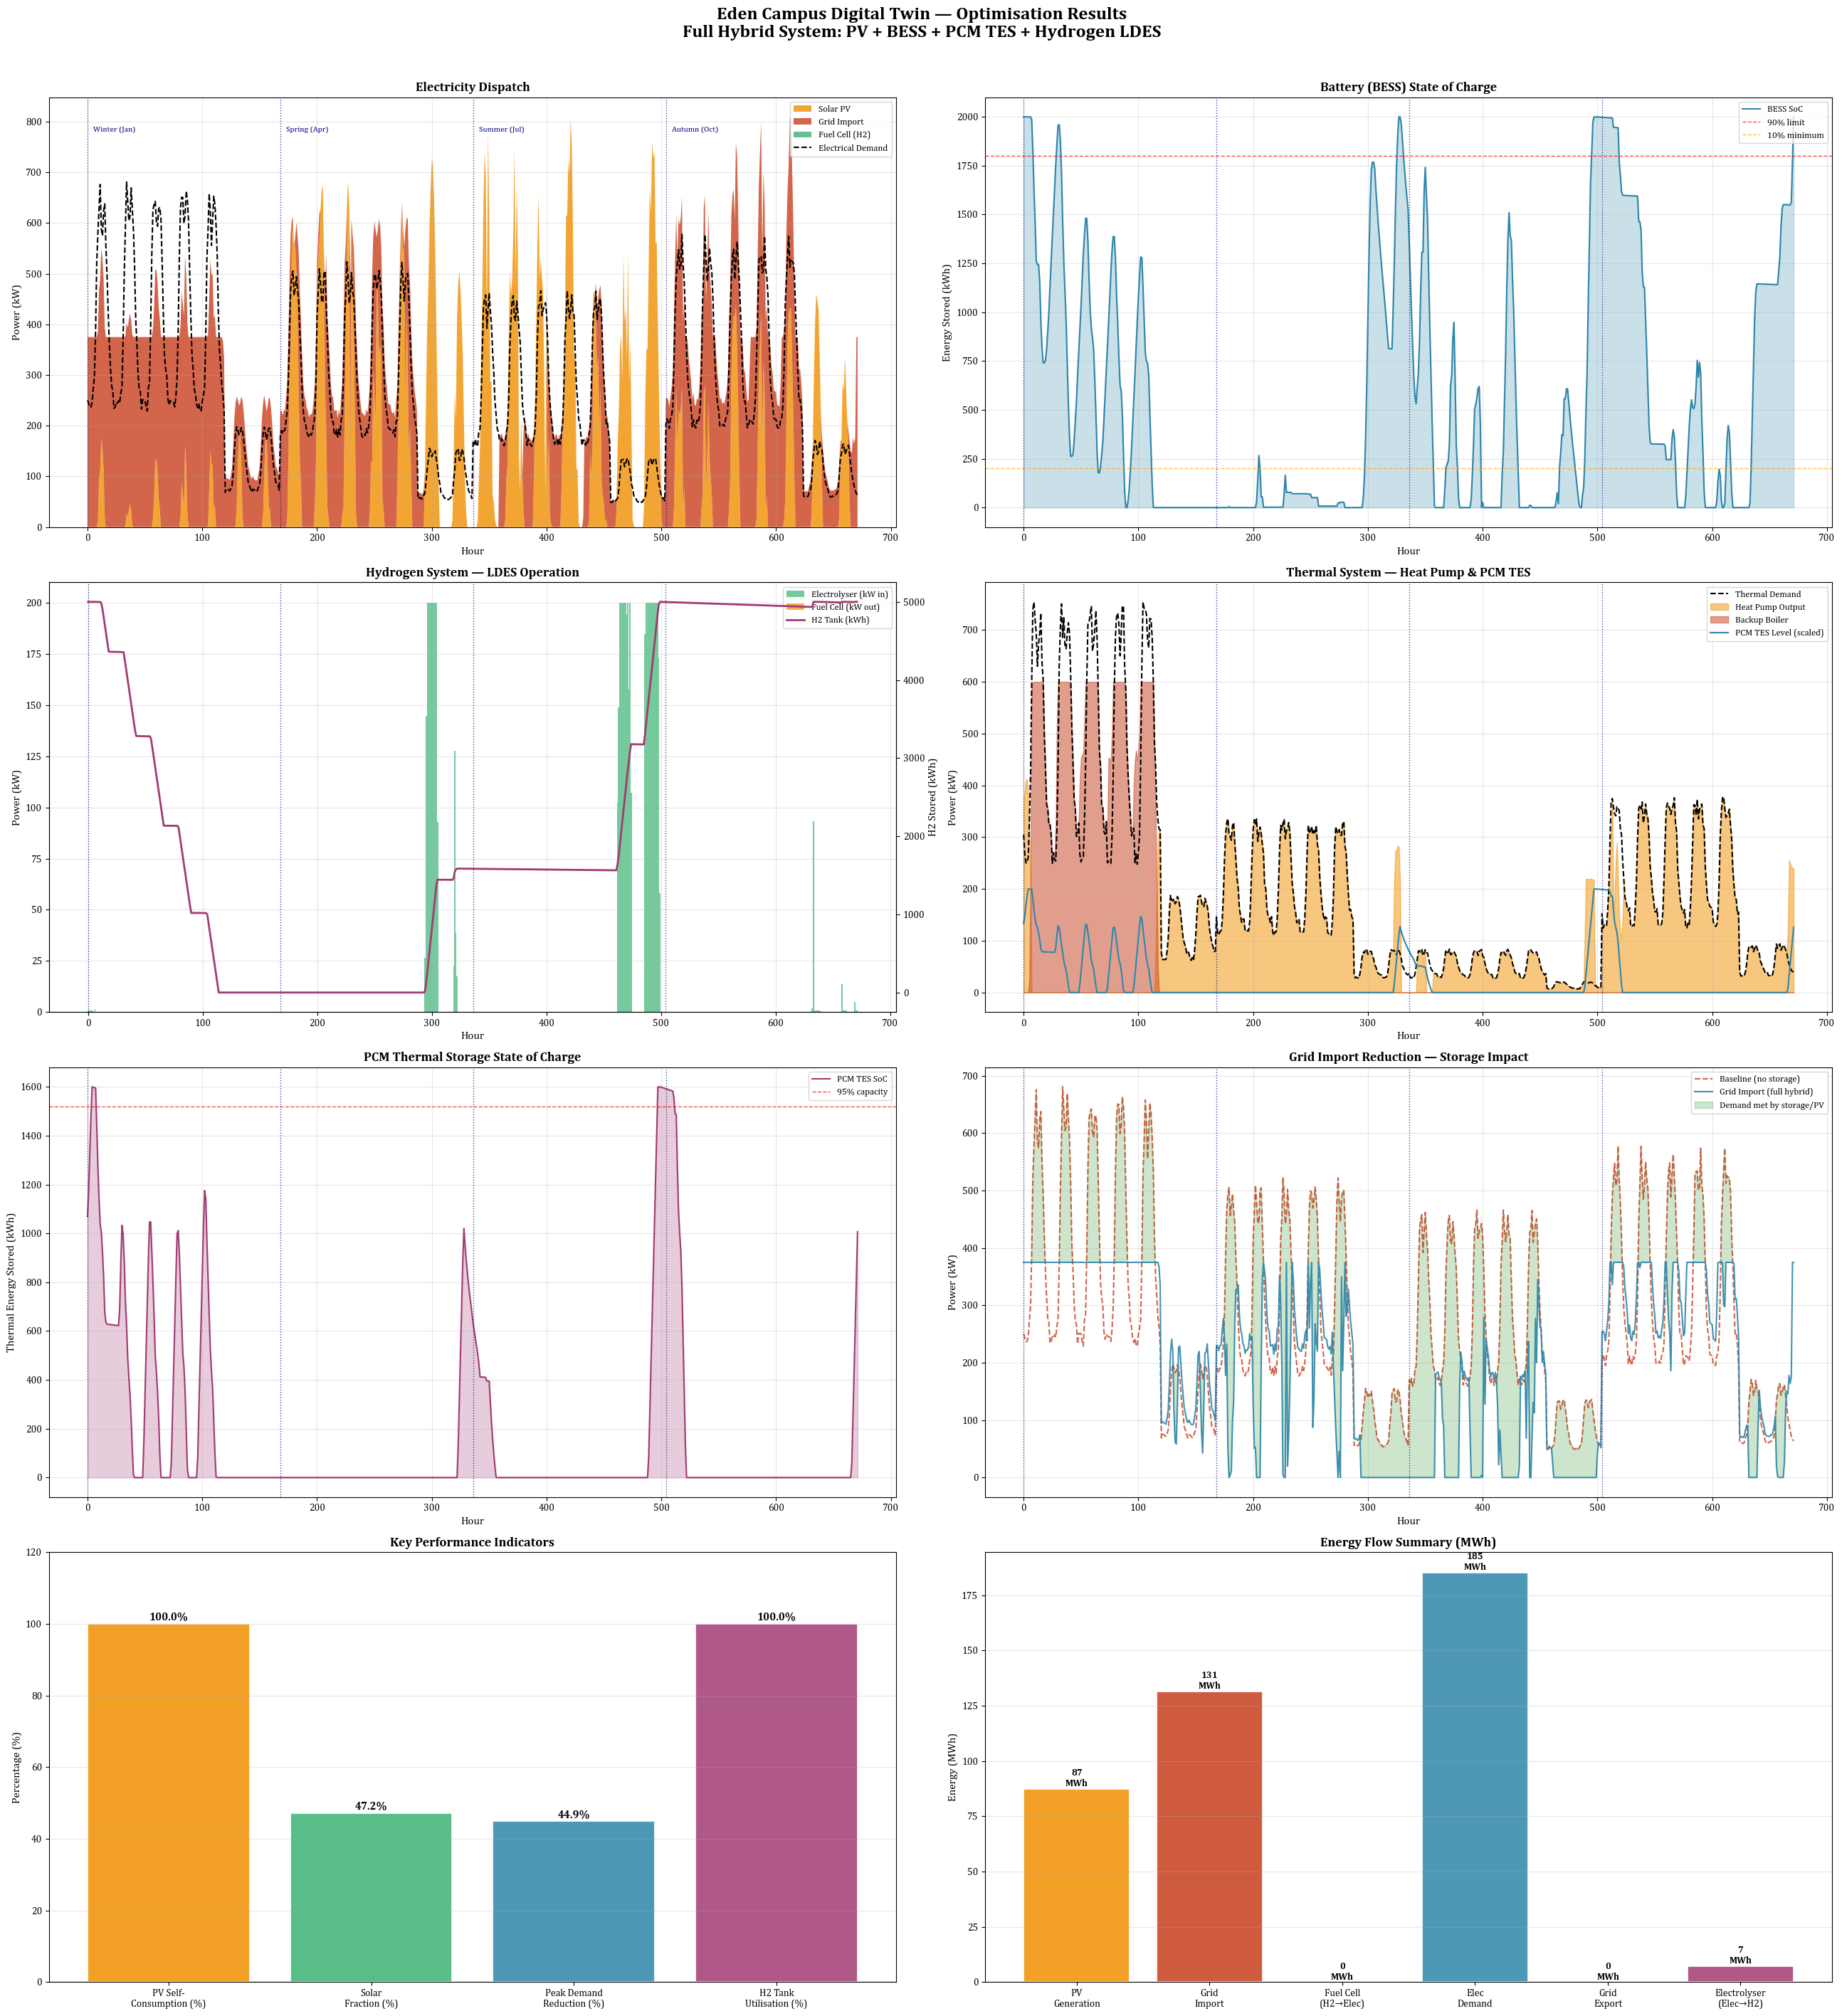


Stage 9 complete — PyPSA results saved!
File saved to: /Users/everythingkrypto/Documents/GitHub/EdenCampus-PhD/EdenCampus_PhD/04_results/figures/eden_campus_digital_twin_results.png


In [4]:
import matplotlib.font_manager as fm
import matplotlib.pyplot as plt
import os

font_path = os.path.expanduser('~/Library/Fonts/Cambria.ttc')
fm.fontManager.addfont(font_path)
plt.rcParams['font.family'] = 'Cambria'

import platform
if platform.system() == 'Windows':
    base = r"C:\Users\sosoq\Documents\GitHub\EdenCampus-PhD\EdenCampus_PhD"
else:
    base = os.path.expanduser("~/Documents/GitHub/EdenCampus-PhD/EdenCampus_PhD")
for folder in ["01_data/weather", "01_data/demand",
               "04_results/figures", "04_results/tables"]:
    os.makedirs(os.path.join(base, folder), exist_ok=True)
hours  = range(len(time_index))
season_labels = ['Winter (Jan)', 'Spring (Apr)',
                 'Summer (Jul)', 'Autumn (Oct)']

fig, axes = plt.subplots(4, 2, figsize=(26, 28))
fig.suptitle(
    'Eden Campus Digital Twin — Optimisation Results\n'
    'Full Hybrid System: PV + BESS + PCM TES + Hydrogen LDES',
    fontsize=18, fontweight='bold', y=1.01)

# ── PLOT 1: Electricity Dispatch ──
ax = axes[0, 0]
ax.stackplot(hours, pv_gen, grid_import,
             fuelcell_p.clip(lower=0),
             labels=['Solar PV', 'Grid Import', 'Fuel Cell (H2)'],
             colors=['#F18F01', '#C73E1D', '#3BB273'], alpha=0.8)
ax.plot(hours, elec_demand, color='black', linewidth=1.5,
        label='Electrical Demand', linestyle='--')
ax.set_title('Electricity Dispatch', fontsize=13, fontweight='bold')
ax.set_ylabel('Power (kW)', fontsize=11)
ax.set_xlabel('Hour', fontsize=11)
ax.legend(fontsize=9, loc='upper right')
ax.grid(True, alpha=0.3)
for i, label in enumerate(season_labels):
    ax.axvline(i * 168, color='navy', linewidth=1.0, linestyle=':', alpha=0.7)
    ax.text(i * 168 + 5, ax.get_ylim()[1] * 0.92,
            label, fontsize=8, color='navy')

# ── PLOT 2: BESS State of Charge ──
ax = axes[0, 1]
ax.plot(hours, bess_soc, color='#2E86AB', linewidth=1.5, label='BESS SoC')
ax.fill_between(hours, bess_soc, alpha=0.25, color='#2E86AB')
ax.axhline(2000 * 0.9, color='red', linewidth=1.0,
           linestyle='--', label='90% limit', alpha=0.7)
ax.axhline(2000 * 0.1, color='orange', linewidth=1.0,
           linestyle='--', label='10% minimum', alpha=0.7)
ax.set_title('Battery (BESS) State of Charge', fontsize=13, fontweight='bold')
ax.set_ylabel('Energy Stored (kWh)', fontsize=11)
ax.set_xlabel('Hour', fontsize=11)
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)
for i in range(4):
    ax.axvline(i * 168, color='navy', linewidth=1.0, linestyle=':', alpha=0.7)

# ── PLOT 3: Hydrogen System ──
ax = axes[1, 0]
ax2_twin = ax.twinx()
ax.bar(hours, electro_p, width=1.0, color='#3BB273',
       alpha=0.7, label='Electrolyser (kW in)')
ax.bar(hours, fuelcell_p.clip(lower=0), width=1.0,
       color='#F18F01', alpha=0.7, label='Fuel Cell (kW out)')
ax2_twin.plot(hours, h2_soc, color='#A23B72',
              linewidth=2.0, label='H2 Tank (kWh)')
ax.set_title('Hydrogen System — LDES Operation', fontsize=13, fontweight='bold')
ax.set_ylabel('Power (kW)', fontsize=11)
ax2_twin.set_ylabel('H2 Stored (kWh)', fontsize=11)
ax.set_xlabel('Hour', fontsize=11)
lines1, labels1 = ax.get_legend_handles_labels()
lines2, labels2 = ax2_twin.get_legend_handles_labels()
ax.legend(lines1 + lines2, labels1 + labels2, fontsize=9)
ax.grid(True, alpha=0.3)
for i in range(4):
    ax.axvline(i * 168, color='navy', linewidth=1.0, linestyle=':', alpha=0.7)

# ── PLOT 4: Thermal System ──
ax = axes[1, 1]
ax.plot(hours, thermal_demand, color='black', linewidth=1.5,
        linestyle='--', label='Thermal Demand')
ax.fill_between(hours, heatpump_p * 3.0, alpha=0.5,
                color='#F18F01', label='Heat Pump Output')
ax.fill_between(hours, boiler_gen, alpha=0.5,
                color='#C73E1D', label='Backup Boiler')
ax.plot(hours, pcm_soc / 8, color='#2E86AB',
        linewidth=1.5, label='PCM TES Level (scaled)')
ax.set_title('Thermal System — Heat Pump & PCM TES', fontsize=13, fontweight='bold')
ax.set_ylabel('Power (kW)', fontsize=11)
ax.set_xlabel('Hour', fontsize=11)
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)
for i in range(4):
    ax.axvline(i * 168, color='navy', linewidth=1.0, linestyle=':', alpha=0.7)

# ── PLOT 5: PCM State of Charge ──
ax = axes[2, 0]
ax.plot(hours, pcm_soc, color='#A23B72', linewidth=1.5, label='PCM TES SoC')
ax.fill_between(hours, pcm_soc, alpha=0.25, color='#A23B72')
ax.axhline(1600 * 0.95, color='red', linewidth=1.0,
           linestyle='--', label='95% capacity', alpha=0.7)
ax.set_title('PCM Thermal Storage State of Charge', fontsize=13, fontweight='bold')
ax.set_ylabel('Thermal Energy Stored (kWh)', fontsize=11)
ax.set_xlabel('Hour', fontsize=11)
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)
for i in range(4):
    ax.axvline(i * 168, color='navy', linewidth=1.0, linestyle=':', alpha=0.7)

# ── PLOT 6: Grid Import Reduction ──
ax = axes[2, 1]
ax.plot(hours, elec_demand, color='#C73E1D', linewidth=1.5,
        linestyle='--', label='Baseline (no storage)', alpha=0.8)
ax.plot(hours, grid_import, color='#2E86AB', linewidth=1.5,
        label='Grid Import (full hybrid)', alpha=0.9)
ax.fill_between(hours, elec_demand, grid_import,
                where=(elec_demand > grid_import),
                interpolate=True, alpha=0.2,
                color='green', label='Demand met by storage/PV')
ax.set_title('Grid Import Reduction — Storage Impact', fontsize=13, fontweight='bold')
ax.set_ylabel('Power (kW)', fontsize=11)
ax.set_xlabel('Hour', fontsize=11)
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)
for i in range(4):
    ax.axvline(i * 168, color='navy', linewidth=1.0, linestyle=':', alpha=0.7)

# ── PLOT 7: KPI Bar Chart ──
ax = axes[3, 0]
kpi_names  = ['PV Self-\nConsumption (%)', 'Solar\nFraction (%)',
               'Peak Demand\nReduction (%)', 'H2 Tank\nUtilisation (%)']
kpi_values = [self_consumption, solar_fraction,
               peak_reduction, h2_util]
bar_colors = ['#F18F01', '#3BB273', '#2E86AB', '#A23B72']
bars = ax.bar(kpi_names, kpi_values, color=bar_colors,
              alpha=0.85, edgecolor='white', linewidth=1.5)
for bar, val in zip(bars, kpi_values):
    ax.text(bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.5,
            f'{val:.1f}%', ha='center', va='bottom',
            fontsize=11, fontweight='bold')
ax.set_title('Key Performance Indicators', fontsize=13, fontweight='bold')
ax.set_ylabel('Percentage (%)', fontsize=11)
ax.set_ylim(min(0, min(kpi_values)) * 1.2, max(kpi_values) * 1.2)
ax.axhline(0, color='black', linewidth=0.8)
ax.grid(True, alpha=0.3, axis='y')

# ── PLOT 8: Energy Flow Summary ──
ax = axes[3, 1]
categories = ['PV\nGeneration', 'Grid\nImport',
               'Fuel Cell\n(H2→Elec)', 'Elec\nDemand',
               'Grid\nExport', 'Electrolyser\n(Elec→H2)']
values = [
    total_pv_gen / 1000,
    total_grid_import / 1000,
    fuelcell_p.clip(lower=0).sum() / 1000,
    total_elec_demand / 1000,
    total_grid_export / 1000,
    electro_p.sum() / 1000,
]
bar_cols = ['#F18F01', '#C73E1D', '#3BB273',
             '#2E86AB', '#888888', '#A23B72']
bars2 = ax.bar(categories, values, color=bar_cols,
               alpha=0.85, edgecolor='white', linewidth=1.5)
for bar, val in zip(bars2, values):
    ax.text(bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.2,
            f'{val:.0f}\nMWh', ha='center', va='bottom',
            fontsize=9.5, fontweight='bold')
ax.set_title('Energy Flow Summary (MWh)', fontsize=13, fontweight='bold')
ax.set_ylabel('Energy (MWh)', fontsize=11)
ax.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
save_path = os.path.join(base, "04_results/figures",
                          "eden_campus_digital_twin_results.png")
plt.savefig(save_path, dpi=300, bbox_inches='tight')
plt.show()
print("\nStage 9 complete — PyPSA results saved!")
print(f"File saved to: {save_path}")